# Function 1

<b> Description of the Sample Application:</b> Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and weak sources.

## Change Log

| Date | Week | Changes Made |
|---|---|---|
| 22/07/2026 | Week 1 | 1. Initial Version with 10 Data Point |
| 06/08/2026 | Week 3 | 1. Consolidated Week 1 (UCB) and Week 2 (EI) logic into a single reusable bayesian_optimization_2d_step function.<br>2. Reduced exploration floor (xi_multiplier: 3.0 to 2.0, 80:20 to 70:30). |
| 13/08/2026 | Week 4 | 1. Input and output data points from Week 3 appended.<br>2. Reduced exploration floor (xi_multiplier: 2.0 to 1.5, 70:30 to 60:40). 
| 20/08/2026 | Week 5 | 1.  Input and output data points from Week 4 appended.<br>2. **Strategy change: switched from global to local (bounded) EI search**, restricted to a window around the current best point (0.731, 0.733), rather than continuing global exploration. <br>3. Reduced exploration floor further (xi_multiplier: 1.5 to 0.25, 60:40 to 20:80) to match the more decisive shift toward exploitation. | 02/02/2026 | Week 6 | 1. Appended Week 5's input and output data point.<br>2. Tested a narrower EI local search window (+/-0.05) for reference/diagnostic purposes.<br>3. Rather than submitting the EI-selected point, manually chose a proximity-stability test point 0.007 from the current best, much closer than EI's acquisition logic would ever select on its own, since EI avoids points immediately adjacent to existing samples (uncertainty there is already near-zero). Justified by having only 2 queries remaining after this week: resolving whether the current best is a genuine sharp peak or an isolated anomaly is higher information-value than another incremental refinement step. ||
| 09/02/2026 | Week 7 | 1. Appended Week 6's input and output data point. Output is positive, of the same order of magnitude as the current best, only 0.007 away. Confirms the proximity-stability hypothesis: this is a genuine.<br>2. Committed to **tight local refinement** (window +/-0.05 around current best, xi_multiplie r =0.05, 5:95 explore:exploit) now that the peak is confirmed real.
| 16/02/2026 | Week 8 | 1. Appended Week 7's input and output data point.<br>2. Only two points are positive (the original best and Week 6's point), both within 0.007 of each other. Every other point tested, even ones only 0.04-0.09 away, are negative. This confirms an extremely narrow peak, tighter than previously assumed.<br>3. Narrowed the local search window further (+/-0.05 to +/-0.005) and tested a direction not yet explored (increasing both x1 and x2 slightly, rather than x2 alone). | | 23/09/2026 | Week 9 | 1. Recorded Week 8's actual output: 1.1663787782344231e-17 -- positive (third positive point found), but does not beat the current best.<br>2. Appended Week 8's input and output data point..<br>3. Week 6 (x1 -0.005 from best) gave 5.61e-16; Week 8 (x1 +0.005 from best, same x2 shift) gave only 1.17e-17, marking a ~48x drop. The peak is steeper on the +x1 side than the -x1 side.<br>4. **Deliberate manual override again:** rather than following the GP's raw EI suggestion (which pointed toward a quadrant already tested negative in Week 3), manually extended the confirmed-productive -x1 direction further past Week 6's point. 
| 30/09/2026 | Week 10 | 1. Appended Week 9's output: 2.0339265002274336e-16, which is the fourth positive point found near the peak.<br>2. Appended Week 9's data point [0.721024, 0.743000].<br>3. **Peak bracketed, not just narrow:** the -x1/+x2 direction now shows a clean monotonic decay (Best > Week6 > Week9, all equally spaced), confirming the original best point is a genuine local maximum in that direction, not just 'somewhere on a slope'. The +x1/+x2 direction (Week 8) decays far more steeply, confirmed asymmetry, not noise.<br>4. EI's own suggestion at the tightest window now points to the one nearby quadrant never tested (x1 increasing, x2 decreasing), filling a genuine gap rather than repeating an already-negative direction. |
| 05/10/2026 | **Week 11** | 1. Appended Week 10's input/output: input `[0.736024, 0.728000]`, output `6.743943716784949e-16`.<br>2. **Strategy check performed, and strategy changed**: with Week 10's point, *all four* diagonal neighbours of the current best (within a 0.014 radius) are now positive. A single best point could be an isolated spike; four consistently positive neighbours look like a genuine basin/cluster instead. <br>3. **New strategy: cluster-informed local search**: introduced a lightweight 2-cluster split (KMeans on sign(y) and log10&#124;y&#124;) to separate the "promising" near-best points from the "background" cluster, then anchored this week's EI search on the **output-weighted centroid of the promising cluster** rather than on the single argmax(Y) point, and tightened the window further (+/-0.004, xi_multiplier = 0.01) given the 20-point evidence base.<br>5. **Visualisation updated**: added a cluster-scatter diagnostic plot and an EI-heatmap around the new centroid-anchored window, and refreshed the weekly dashboard/convergence plot with Week 10's real outcome. |||


# Weekly Progress Log

| Week | Method | Exploration:Exploitation | Query (x1, x2) | Output (y) | Best-so-far |
|---|---|---|---|---|---|
| Initial | Provided data (10 points) | - | - | - | 7.710875e-16 |
| 1 | GP-UCB (β=2.5), space-filling exploration | 90:10 | (0.617450, 0.872483) | -4.579196e-42 | 7.710875e-16 |
| 2 | GP-Expected Improvement (EI), exploration floor via scaled xi (xi_multiplier=3.0) | 80:20 | (0.785234, 0.798657) | 1.170424e-37 | 7.710875e-16 |
| 3 | GP-Expected Improvement (EI), reduced exploration floor (xi_multiplier=2.0) | 70:30 | (0.818791, 0.711409) | -5.679812e-31 | 7.710875e-16 |
| 4 | GP-Expected Improvement (EI), further reduced exploration floor (xi_multiplier=1.5) | 60:40 | (0.409396, 0.040268) | -6.737500e-102 | 7.710875e-16 |
| 5 | GP-Expected Improvement (EI), local search bounded to +/-0.15 around the current best (xi_multiplier=0.25) | 20:80 | (0.770285, 0.746087) | -4.703971e-26 | 7.710875e-16 |
| 6 | Deliberate proximity-stability test (manual override) | 0:100 | (0.726024, 0.738000) | 5.606704e-16 | 7.710875e-16 |
| 7 | GP-Expected Improvement (EI), tight local refinement (window +/-0.05, xi_multiplier = 0.05) | 5:95 | (0.732030, 0.783000) | -1.028481e-24 | 7.710875e-16 |
| 8 | GP-Expected Improvement (EI), extremely narrow local refinement (window +/-0.005, xi_multiplier = 0.02) | 2:98 | (0.736024, 0.738000) | 1.166379e-17 | 7.710875e-16 |
| 9 | Manual override: extending the confirmed-productive -x1,+x2 direction past Week 6 | 0:100 | (0.721024, 0.743000) | 2.033927e-16 | 7.710875e-16 |
| 10 | GP-Expected Improvement (EI), extremely narrow window (+/-0.005) targeting the last untested (+x1,-x2) quadrant | 2:98 | (0.736024, 0.728000) | **6.743944e-16** | 7.710875e-16 |
| **11** | **GP-Expected Improvement (EI), cluster-informed local search** - anchored on the output-weighted centroid of the "promising cluster" (window +/-0.004, xi_multiplier=0.01) | ~1:99 | - | - | 7.710875e-16 |

In [117]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel, Matern
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.stats import norm
from plotting_utils import plot_2d_bo_state, plot_convergence
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import numpy as np

# Load and Analyse the Data

In [7]:
# File Names
input_file  = "initial_inputs.npy"
output_file = "initial_outputs.npy"

# Load the Files
X              = np.load(input_file)
Y              = np.load(output_file)

In [10]:
# New data from Week 1 submission
X_w1_new_point = np.array([0.644295, 0.872483]      , dtype=np.float64)    # from input.txt
Y_w1_new_point = np.array([-4.57919574117409e-42]   , dtype=np.float64)    # from output.txt

# New data from Week 2 submission
X_w2_new_point = np.array([0.785234, 0.798657]      , dtype=np.float64)    # from input.txt
Y_w2_new_point = np.array([1.1704238583798859e-37]  , dtype=np.float64)   # from output.txt

# New data from Week 3 submission
X_w3_new_point = np.array([0.818791, 0.711409]      , dtype=np.float64)   # from input.txt
Y_w3_new_point = np.array([-5.679811964041589e-31]  , dtype=np.float64)   # from output.txt

# New data from Week 4 submission
X_w4_new_point = np.array([0.409396, 0.040268]      , dtype=np.float64)   # from input.txt
Y_w4_new_point = np.array([-6.7375004083242144e-102], dtype=np.float64)   # from output.txt

# New data from Week 5 submission
X_w5_new_point = np.array([0.770285, 0.746087]      , dtype=np.float64)   # from input.txt
Y_w5_new_point = np.array([-4.7039714109697477e-26] , dtype=np.float64)   # from output.txt

# New data from Week 6 submission
X_w6_new_point = np.array([0.726024, 0.738000]      , dtype=np.float64)   # from input.txt
Y_w6_new_point = np.array([5.606704199651088e-16]   , dtype=np.float64)   # from output.txt

# New data from Week 7 submission
X_w7_new_point = np.array([0.73203, 0.783]          , dtype=np.float64)  # from input.txt
Y_w7_new_point = np.array([-1.0284805649443051e-24] , dtype=np.float64)  # from output.txt

# New data from Week 8 submission
X_w8_new_point = np.array([0.736024, 0.738000]      , dtype=np.float64)   # from input.txt
Y_w8_new_point = np.array([1.1663787782344231e-17]  , dtype=np.float64)   # from output.txt

# New data from Week 9 submission
X_w9_new_point = np.array([0.721024, 0.743000]      , dtype=np.float64)   # from input.txt
Y_w9_new_point = np.array([2.0339265002274336e-16]  , dtype=np.float64)   # from output.txt

# New data from Week 10 submission
X_w10_new_point = np.array([0.736024, 0.728000]      , dtype=np.float64)   # from input.txt
Y_w10_new_point = np.array([6.743943716784949e-16]   , dtype=np.float64)   # from output.txt

In [12]:
# Append the new data points
X_updated      = np.vstack((X, X_w1_new_point
                             , X_w2_new_point
                             , X_w3_new_point
                             , X_w4_new_point
                             , X_w5_new_point
                             , X_w6_new_point
                             , X_w7_new_point
                             , X_w8_new_point
                             , X_w9_new_point
                             , X_w10_new_point
                           ))
Y_updated      = np.append(Y, [Y_w1_new_point
                            , Y_w2_new_point
                            , Y_w3_new_point
                            , Y_w4_new_point
                            , Y_w5_new_point
                            , Y_w6_new_point
                            , Y_w7_new_point
                            , Y_w8_new_point
                            , Y_w9_new_point
                            , Y_w10_new_point
                              ])


In [14]:
print(X_updated)
print(Y_updated)

# Save the updated arrays
#np.save(r"initial_inputs.npy", X_updated)
#np.save(r"initial_outputs.npy", Y_updated)

[[0.31940389 0.76295937]
 [0.57432921 0.8798981 ]
 [0.73102363 0.73299988]
 [0.84035342 0.26473161]
 [0.65011406 0.68152635]
 [0.41043714 0.1475543 ]
 [0.31269116 0.07872278]
 [0.68341817 0.86105746]
 [0.08250725 0.40348751]
 [0.88388983 0.58225397]
 [0.644295   0.872483  ]
 [0.785234   0.798657  ]
 [0.818791   0.711409  ]
 [0.409396   0.040268  ]
 [0.770285   0.746087  ]
 [0.726024   0.738     ]
 [0.73203    0.783     ]
 [0.736024   0.738     ]
 [0.721024   0.743     ]
 [0.736024   0.728     ]]
[ 1.32267704e-079  1.03307824e-046  7.71087511e-016  3.34177101e-124
 -3.60606264e-003 -2.15924904e-054 -2.08909327e-091  2.53500115e-040
  3.60677119e-081  6.22985647e-048 -4.57919574e-042  1.17042386e-037
 -5.67981196e-031 -6.73750041e-102 -4.70397141e-026  5.60670420e-016
 -1.02848056e-024  1.16637878e-017  2.03392650e-016  6.74394372e-016]


In [16]:
# Assign X = X_updated and Y = Y_updated
X          = X_updated
Y          = Y_updated

# Analyse the Input Data
print("Input  Shape:", X.shape)
print("Inputs:\n", X)
print()

# Analyse the Output Data
print("Output Shape:", Y.shape)
print("Outputs:\n", Y)
print()
print("Minimum and Maximum Values of Output:\n")
print("Min:", Y.min(), " Max:", Y.max())
print("Best point:", X[np.argmax(Y)], "-> Output =", Y.max())
print()

# Converting the Input and Output into a DataFram
df           = pd.DataFrame(X, columns = [f'Input_{i+1}' for i in range(X.shape[1])])
df['Output'] = Y
print("Data Frame:\n", df)

Input  Shape: (20, 2)
Inputs:
 [[0.31940389 0.76295937]
 [0.57432921 0.8798981 ]
 [0.73102363 0.73299988]
 [0.84035342 0.26473161]
 [0.65011406 0.68152635]
 [0.41043714 0.1475543 ]
 [0.31269116 0.07872278]
 [0.68341817 0.86105746]
 [0.08250725 0.40348751]
 [0.88388983 0.58225397]
 [0.644295   0.872483  ]
 [0.785234   0.798657  ]
 [0.818791   0.711409  ]
 [0.409396   0.040268  ]
 [0.770285   0.746087  ]
 [0.726024   0.738     ]
 [0.73203    0.783     ]
 [0.736024   0.738     ]
 [0.721024   0.743     ]
 [0.736024   0.728     ]]

Output Shape: (20,)
Outputs:
 [ 1.32267704e-079  1.03307824e-046  7.71087511e-016  3.34177101e-124
 -3.60606264e-003 -2.15924904e-054 -2.08909327e-091  2.53500115e-040
  3.60677119e-081  6.22985647e-048 -4.57919574e-042  1.17042386e-037
 -5.67981196e-031 -6.73750041e-102 -4.70397141e-026  5.60670420e-016
 -1.02848056e-024  1.16637878e-017  2.03392650e-016  6.74394372e-016]

Minimum and Maximum Values of Output:

Min: -0.0036060626443634764  Max: 7.710875114502849

# Data Exploration

In [19]:
# Basic Staistics
print("Display Basic Statistics for the Dataset\n",df.describe())

Display Basic Statistics for the Dataset
          Input_1    Input_2        Output
count  20.000000  20.000000  2.000000e+01
mean    0.628365   0.614705 -1.803031e-04
std     0.211389   0.270478  8.063401e-04
min     0.082507   0.040268 -3.606063e-03
25%     0.533356   0.537562 -1.144799e-42
50%     0.723524   0.735500  6.793724e-80
75%     0.744589   0.767970  2.915947e-18
max     0.883890   0.879898  7.710875e-16


In [21]:
# Check for Missing Values in the Data Set
print("Missing Values in the Dataset\n",df.isnull().sum())

Missing Values in the Dataset
 Input_1    0
Input_2    0
Output     0
dtype: int64


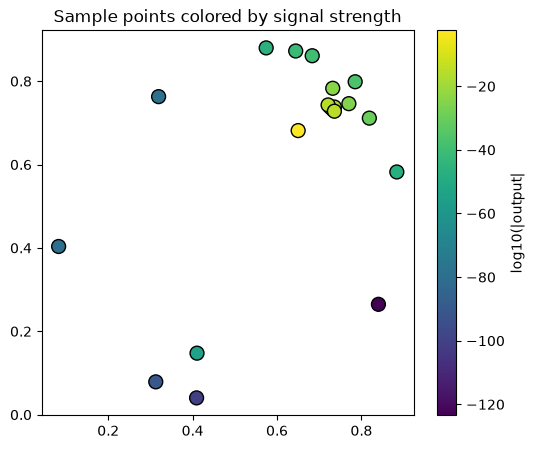

In [23]:
# Scatter Plot
magnitude = np.log10(np.abs(Y) + 1e-300)
fig, ax   = plt.subplots(figsize = (6,5))
sc        = ax.scatter(X[:,0], X[:,1], c = magnitude, cmap = 'viridis', s = 100, edgecolor = 'black')
plt.colorbar(sc, label = 'log10(|output|')
ax.set_title('Sample points colored by signal strength')
plt.show()

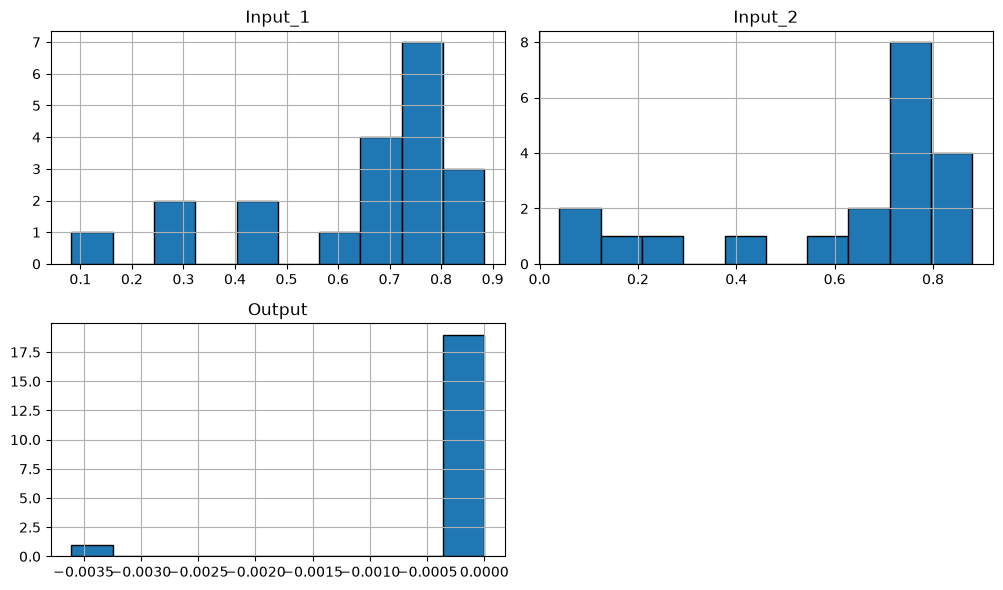

In [25]:
# Plot Histogram Visualisation for the columns of the DataFrame
df.hist(figsize = (10, 6), bins = 10, edgecolor = 'black' )
plt.tight_layout()
plt.show()

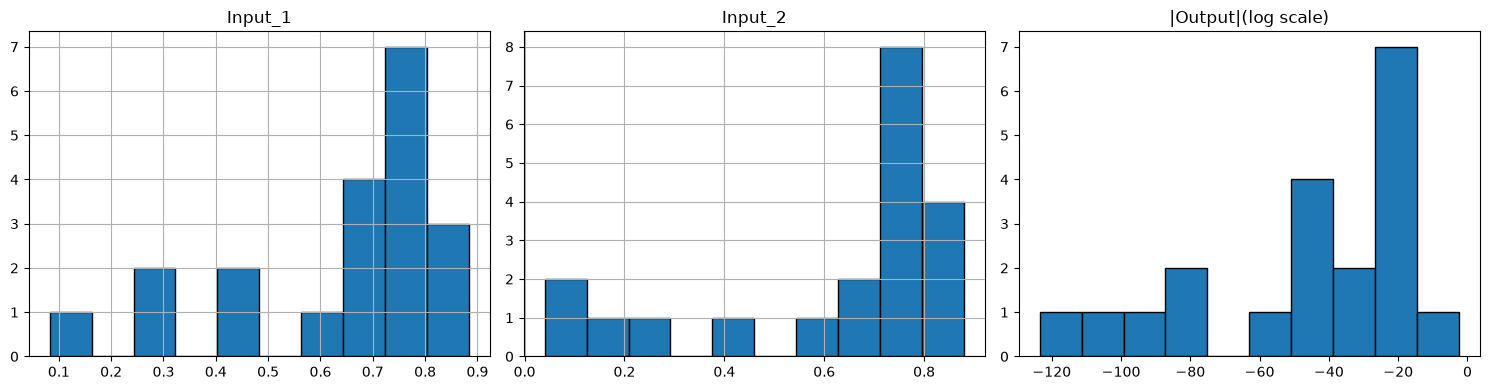

In [26]:
# In the above histogram for the output column, almost every bar seems to be crammed into a single bin near zero, which is not very informative.
# Plotting the column histograms using log scale for Output column
fig, axes = plt.subplots(1,3, figsize = (15,4))

df['Input_1'].hist(ax = axes[0], bins = 10, edgecolor = 'black')
axes[0].set_title('Input_1')

df['Input_2'].hist(ax = axes[1], bins = 10, edgecolor = 'black')
axes[1].set_title('Input_2')

magnitude = np.where(Y != 0, np.log10(np.abs(Y) + 1e-300), np.nan)
axes[2].hist(magnitude, bins = 10, edgecolor = 'black')
axes[2].set_title('|Output|(log scale)')


plt.tight_layout()
plt.show()

# Nearest-Pair Check

In [30]:
D      = squareform(pdist(X))
i, j   = np.unravel_index(np.argmin(D + np.eye(len(X))*99), D.shape)
print(f"Closest pair: idx {i} & {j}, distance={D[i,j]:.4f}, y_i={Y[i]:.3e}, y_j={Y[j]:.3e}")

Closest pair: idx 2 & 15, distance=0.0071, y_i=7.711e-16, y_j=5.607e-16


# Initialize Gaussian Process

In [33]:
#Define the kernel and initialise the GP model

# Week 1 ( Using RBF GP Surrogate )
kernel_rbf   = ConstantKernel(1.0) * RBF(length_scale = 0.2, length_scale_bounds = (0.02, 1.0)) \
                + WhiteKernel(noise_level = 1e-6, noise_level_bounds = (1e-10, 1e-2))
gpr          = GaussianProcessRegressor(kernel = kernel_rbf, normalize_y = True, n_restarts_optimizer = 10, random_state = 0 )

# Fit the Gaussian Processes to existing data

In [36]:
# Train the model

# Week 1 fit to RBF GP Surrugate
gpr.fit(X, Y)
print("Learned kernel (Week 1): ", gpr.kernel_)

Learned kernel (Week 1):  1.15**2 * RBF(length_scale=0.0541) + WhiteKernel(noise_level=1e-10)


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 1: Compute the UCB acquisition function

- UCB(x)=μ(x)+β⋅σ(x)
- A high beta favors exploration (uncertainty) over exploitation (predicted mean).
- Week 1 uses beta = 2.5, reflecting the 90:10 exploration-heavy strategy.

In [40]:
grid_res   = 150
xs         = np.linspace(0, 1, grid_res)
ys         = np.linspace(0, 1, grid_res)
gx, gy     = np.meshgrid(xs, ys)
candidates = np.column_stack([gx.ravel(), gy.ravel()])

mu, std    = gpr.predict(candidates, return_std = True)

# Setting a higher beta(= 2.5) for Week -1
beta       = 2.5
ucb        = mu + beta * std

best_ucb_idx = np.argmax(ucb)
next_point   = candidates[best_ucb_idx]

print(f"Suggested next Query Point: {next_point}")
print(f"Predicted Mean(μ): {mu[best_ucb_idx]:.6e}")
print(f"Predicted Std (σ): {std[best_ucb_idx]:.6e}")
print(f"UCB Score: {ucb[best_ucb_idx]:.6e}")

Suggested next Query Point: [0.29530201 0.20134228]
Predicted Mean(μ): -1.601256e-04
Predicted Std (σ): 9.018186e-04
UCB Score: 2.094421e-03


# Perform Visualisation ( Week 1 )

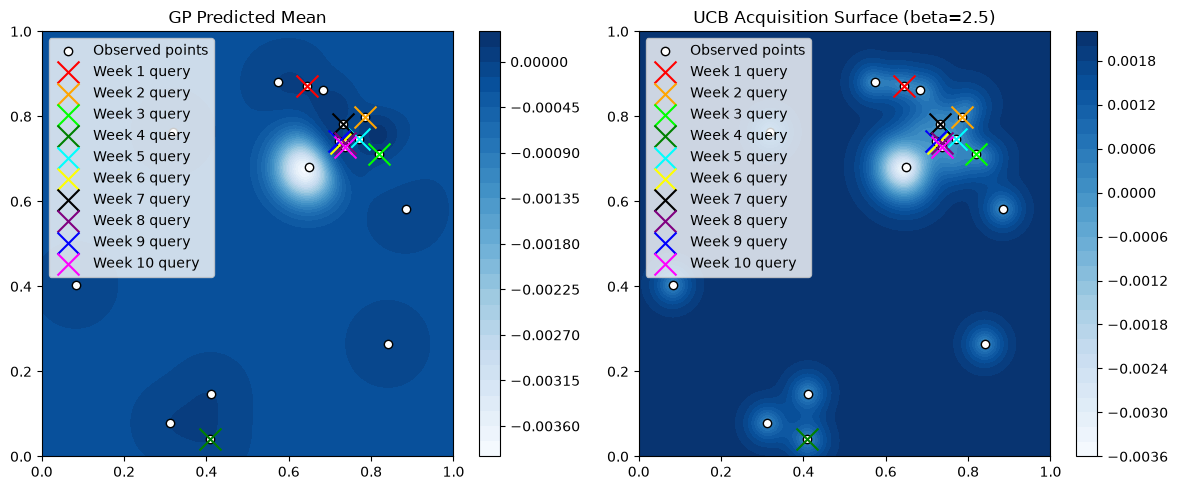

In [45]:
fig, axes  = plt.subplots(1,2, figsize = (12, 5))

# Predicted mean surface
c0 = axes[0].contourf(gx, gy, mu.reshape(gx.shape), levels=30, cmap="Blues")
axes[0].scatter(X[:, 0], X[:, 1] , c = "white" , edgecolor = "black", label = "Observed points")
axes[0].scatter(*X_w1_new_point  , c = "red"   , marker    = "x"    , s=250, label = "Week 1 query")
axes[0].scatter(*X_w2_new_point  , c = "orange", marker    = "x"    , s=250, label = "Week 2 query")
axes[0].scatter(*X_w3_new_point  , c = "lime"  , marker    = "x"    , s=250, label = "Week 3 query")
axes[0].scatter(*X_w4_new_point  , c = "green" , marker    = "x"    , s=250, label = "Week 4 query")
axes[0].scatter(*X_w5_new_point  , c = "cyan"  , marker    = "x"    , s=250, label = "Week 5 query")
axes[0].scatter(*X_w6_new_point  , c = "yellow", marker    = "x"    , s=250, label = "Week 6 query")
axes[0].scatter(*X_w7_new_point  , c = "black" , marker    = "x"    , s=250, label = "Week 7 query")
axes[0].scatter(*X_w8_new_point  , c = "purple", marker    = "x"    , s=250, label = "Week 8 query")
axes[0].scatter(*X_w9_new_point  , c = "blue"  , marker    = "x"    , s=250, label = "Week 9 query")
axes[0].scatter(*X_w10_new_point , c = "magenta",marker    = "x"    , s=250, label = "Week 10 query")

axes[0].set_title("GP Predicted Mean")
axes[0].legend(loc='upper left')
fig.colorbar(c0, ax=axes[0])

# UCB acquisition surface
c1 = axes[1].contourf(gx, gy, ucb.reshape(gx.shape), levels=30, cmap="Blues")
axes[1].scatter(X[:, 0], X[:, 1] , c = "white" , edgecolor = "black", label = "Observed points")
axes[1].scatter(*X_w1_new_point  , c = "red"   , marker    = "x"    , s     = 250, label = "Week 1 query")
axes[1].scatter(*X_w2_new_point  , c = "orange", marker    = "x"    , s     = 250, label = "Week 2 query")
axes[1].scatter(*X_w3_new_point  , c = "lime"  , marker    = "x"    , s     = 250, label = "Week 3 query")
axes[1].scatter(*X_w4_new_point  , c = "green" , marker    = "x"    , s     = 250, label = "Week 4 query")
axes[1].scatter(*X_w5_new_point  , c = "cyan"  , marker    = "x"    , s     = 250, label = "Week 5 query")
axes[1].scatter(*X_w6_new_point  , c = "yellow", marker    = "x"    , s     = 250, label = "Week 6 query")
axes[1].scatter(*X_w7_new_point  , c = "black" , marker    = "x"    , s     = 250, label = "Week 7 query")
axes[1].scatter(*X_w8_new_point  , c = "purple", marker    = "x"    , s     = 250, label = "Week 8 query")
axes[1].scatter(*X_w9_new_point  , c = "blue"  , marker    = "x"    , s     = 250, label = "Week 9 query")
axes[1].scatter(*X_w10_new_point , c = "magenta",marker    = "x"    , s     = 250, label = "Week 10 query")

axes[1].set_title("UCB Acquisition Surface (beta=2.5)")
axes[1].legend(loc='upper left')
fig.colorbar(c1, ax=axes[1])

plt.tight_layout()
plt.show()

# Week 2: Compute the EI acquisition Function

In [48]:
grid_res = 150

# Define Expected Improvement Acquisition Function
def expected_improvement(mu, sigma, y_best, xi):
    """EI = E[max(f(x) - f(x_best), 0)]"""
    sigma   = np.maximum(sigma, 1e-9)
    z       = (mu - y_best - xi) / sigma
    ei      = (mu - y_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

# Define Bayesian Optimisation Function for Week2
def bayesian_optimization_2d_step(X_samples, y_samples, bounds, xi_multiplier = 3.0, grid_res = grid_res, nu = 2.5):
    """
    Single-step 2D Bayesian Optimization, fit a Matern GP, evaluate EI over a dense candidate grid, and return the next query point.
    """

    # Using Matern GP Surrogate
    kernel_matern = ConstantKernel(1.0) * Matern(length_scale = 0.2, length_scale_bounds = (0.02, 1.0), nu = nu) \
                        + WhiteKernel(noise_level = 1e-6, noise_level_bounds = (1e-10, 1e-2))
    
    grp_matern    = GaussianProcessRegressor(kernel = kernel_matern, normalize_y = True, n_restarts_optimizer = 10, random_state = 0 )

    grp_matern.fit(X_samples, y_samples)
    
    #print("Learned kernel (Week 2): ", grp_matern.kernel_)
    
    # Grid sampling: build a candidate grid over the bounds
    axes         = [np.linspace(b[0], b[1], grid_res) for b in bounds]
    mesh         = np.meshgrid(*axes)
    candidates   = np.column_stack([m.ravel() for m in mesh])

    mu, sigma    = grp_matern.predict(candidates, return_std = True)
    
    xi           = xi_multiplier * y_samples.std()
    ei           = expected_improvement(mu, sigma, y_samples.max(), xi=xi)

    best_idx     = np.argmax(ei)
    X_next       = candidates[best_idx]

    return {
        'gp': grp_matern, 'mesh': mesh, 'candidates': candidates,
        'mu': mu, 'sigma': sigma, 'ei': ei, 'xi': xi,
        'X_next': X_next, 'ei_at_next': ei[best_idx],
        'mu_at_next': mu[best_idx], 'sigma_at_next': sigma[best_idx],
    }
    

result           = bayesian_optimization_2d_step(X, Y, bounds = [(0, 0.999999), (0, 0.999999)], xi_multiplier = 3.0 )

next_point       = result['X_next']

print("Learned kernel          :", result['gp'].kernel_)
print(f"Exploration floor (xi) : {result['xi']:.6e}")
print(f"\nNext query point (EI): {next_point}")
print(f"EI value at next point : {result['ei_at_next']:.6e}")
print(f"Predicted mean (mu)    : {result['mu_at_next']:.6e}")
print(f"Predicted std (sigma)  : {result['sigma_at_next']:.6e}")

Learned kernel          : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Exploration floor (xi) : 2.357769e-03

Next query point (EI): [0.38254995 0.9932876 ]
EI value at next point : 2.731209e-06
Predicted mean (mu)    : -1.554976e-04
Predicted std (sigma)  : 1.041864e-03


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 2 Visualisation

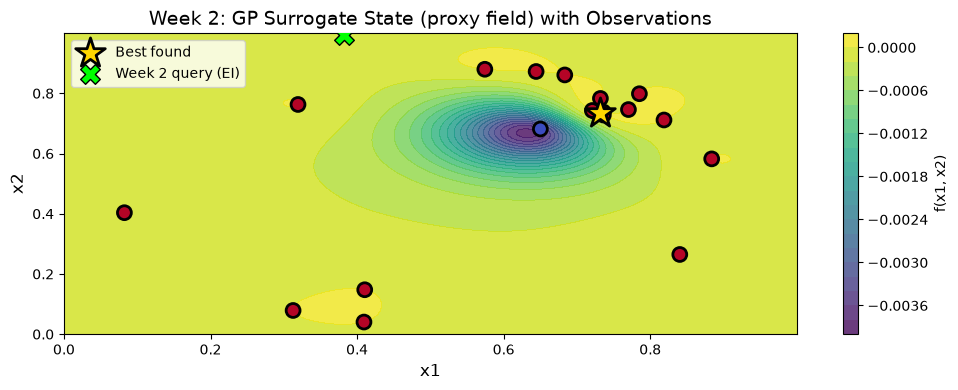

In [51]:
gx, gy   = result['mesh']
Z        = result['mu'].reshape(gx.shape)

fig, ax  = plot_2d_bo_state( gx, gy, Z, X, Y, title = "Week 2: GP Surrogate State (proxy field) with Observations")
ax.scatter(*next_point, marker = 'X', s = 200, c = 'lime', edgecolor = 'black', label = 'Week 2 query (EI)', zorder = 12)
ax.legend(loc = 'upper left')
plt.show()

# Week 3: Consolidated Bayesian Optimization Function

In [54]:
# Define UCB Acquisition Function
def upper_confidence_bound(mu, sigma, beta=2.0):
    """UCB = mean + beta * std"""
    return mu + beta * sigma

# Define Expected Improvement Acquisition Function
def expected_improvement(mu, sigma, y_best, xi):
    """EI = E[max(f(x) - f(x_best), 0)]"""
    sigma   = np.maximum(sigma, 1e-9)
    z       = (mu - y_best - xi) / sigma
    ei      = (mu - y_best - xi) * norm.cdf(z) + sigma * norm.pdf(z)
    ei[sigma < 1e-9] = 0.0
    return ei

# Week 3: Consolidated Bayesian Optimization Function
def bayesian_optimization_2d_step(X_samples, y_samples, bounds, acquisition = 'ei',
                                   xi_multiplier = 2.0, beta = 2.0, grid_res = 150, nu = 2.5,
                                   plot = True, week_label = 'Week'):

    kernel_matern = ConstantKernel(1.0) * Matern(length_scale = 0.2, length_scale_bounds =( 0.02, 1.0), nu = nu) \
                        + WhiteKernel(noise_level = 1e-6, noise_level_bounds = (1e-10, 1e-2))

    grp_matern   = GaussianProcessRegressor(kernel = kernel_matern, normalize_y = True,
                                            n_restarts_optimizer = 10, random_state = 0)
    grp_matern.fit(X_samples, y_samples)

    # Grid sampling: build a candidate grid over the bounds
    axes         = [np.linspace(b[0], b[1], grid_res) for b in bounds]
    mesh         = np.meshgrid(*axes)
    candidates   = np.column_stack([m.ravel() for m in mesh])

    mu, sigma    = grp_matern.predict(candidates, return_std = True)

    if acquisition == 'ei':
        xi       = xi_multiplier * y_samples.std()
        acq_vals = expected_improvement(mu, sigma, y_samples.max(), xi=xi)
    else:
        xi       = None
        acq_vals = upper_confidence_bound(mu, sigma, beta = beta)

    best_idx     = np.argmax(acq_vals)
    X_next       = candidates[best_idx]

    print(f"--- {week_label}: Bayesian Optimization ---")
    print(f"Learned kernel        : {grp_matern.kernel_}")
    if xi is not None:
        print(f"Acquisition           : EI (xi = {xi:.6e})")
    else:
        print(f"Acquisition           : UCB (beta = {beta})")
    print(f"Next query point      : {X_next}")
    print(f"Acquisition value     : {acq_vals[best_idx]:.6e}")
    print(f"Predicted mean (mu)   : {mu[best_idx]:.6e}")
    print(f"Predicted std (sigma) : {sigma[best_idx]:.6e}")
    print(f"Best value so far     : {y_samples.max():.6e} at {X_samples[np.argmax(y_samples)]}")

    if plot:
        gx, gy    = mesh
        Z         = mu.reshape(gx.shape)
        fig, ax   = plot_2d_bo_state(gx, gy, Z, X_samples, y_samples,
                                     title = f"{week_label}: GP Surrogate State")
        ax.scatter(*X_next, marker = 'X', s = 200, c = 'lime', edgecolor = 'black',
                   label = f'{week_label} query ({acquisition.upper()})', zorder = 12)
        ax.legend(loc = 'upper left')
        plt.show()

    return {
        'gp': grp_matern, 'mesh': mesh, 'candidates': candidates,
        'mu': mu, 'sigma': sigma, 'acq_vals': acq_vals, 'xi': xi,
        'X_next': X_next, 'acq_at_next': acq_vals[best_idx],
        'mu_at_next': mu[best_idx], 'sigma_at_next': sigma[best_idx],
        'best_so_far': y_samples.max(),
    }


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 3: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.571846e-03)
Next query point      : [0.38926136 0.97986479]
Acquisition value     : 2.112889e-05
Predicted mean (mu)   : -1.502330e-04
Predicted std (sigma) : 1.039658e-03
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


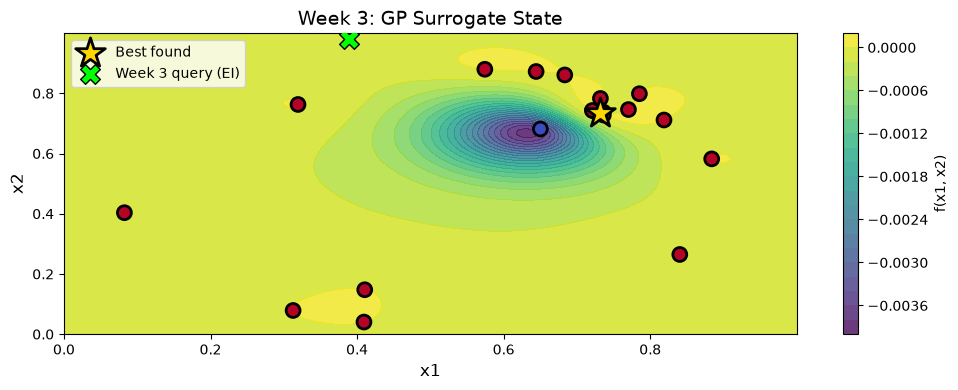

In [56]:
# Run the consolidated function for Week 3
# xi_multiplier reduced from 3.0 (Week 2) to 2.0 -- ~70:30 exploration:exploitation
# Uses the 12-point dataset (X, Y) updated above (Week 1 + Week 2 feedback appended)
result_w3        = bayesian_optimization_2d_step(
    X, Y, bounds = [(0, 0.999999), (0, 0.999999)],
    acquisition  = 'ei', xi_multiplier = 2.0, week_label = 'Week 3'
)

next_point_w3 = result_w3['X_next']

# Week 4: Calling the consolidated Bayesian Optimisation Function
Calling the consolidated function with xi_multiplier reduced from 2.0 (Week 3) to 1.5 to facilitate 60:40 exploration:exploitation

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 4: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.178885e-03)
Next query point      : [0.38926136 0.96644199]
Acquisition value     : 4.958062e-05
Predicted mean (mu)   : -1.461400e-04
Predicted std (sigma) : 1.037510e-03
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


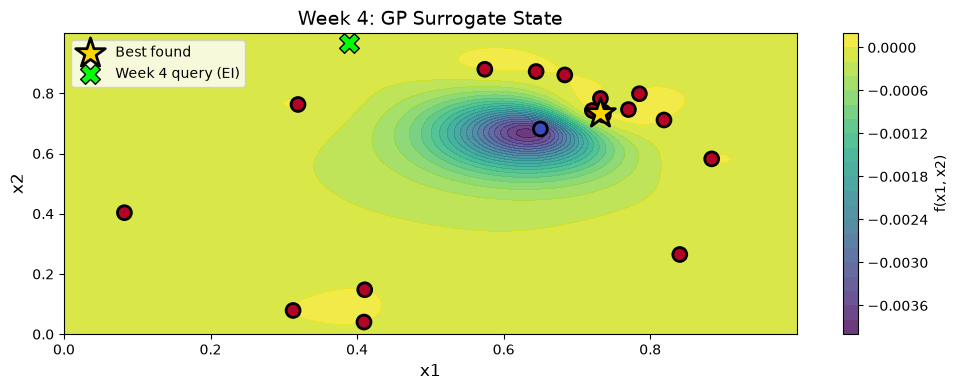

In [59]:
result_w4        = bayesian_optimization_2d_step(
    X, Y, bounds = [(0, 0.999999), (0, 0.999999)],
    acquisition  = 'ei', xi_multiplier = 1.5, week_label = 'Week 4'
)

next_point_w4 = result_w4['X_next']

# Week5: Comparing global EI vs. a local-window-restricted EI

In [62]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)

best_point_check = X[np.argmax(Y)]

# --- Global candidates (whole domain) ---
grid_res = 150
xs = np.linspace(0, 0.999999, grid_res)
gx_g, gy_g = np.meshgrid(xs, xs)
candidates_global = np.column_stack([gx_g.ravel(), gy_g.ravel()])
mu_g, sigma_g = gp_check.predict(candidates_global, return_std=True)

for xi_mult in [1.0, 0.75, 0.5]:
    xi = xi_mult * Y.std()
    ei = expected_improvement(mu_g, sigma_g, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_global[idx] - best_point_check)
    print(f"GLOBAL  xi_mult={xi_mult}: next={candidates_global[idx]}, dist_to_best={dist:.4f}")

print()

# --- Local candidates (window around current best) ---
window = 0.15
lo = np.clip(best_point_check - window, 0, 0.999999)
hi = np.clip(best_point_check + window, 0, 0.999999)
xs_l = np.linspace(lo[0], hi[0], grid_res)
ys_l = np.linspace(lo[1], hi[1], grid_res)
gx_l, gy_l = np.meshgrid(xs_l, ys_l)
candidates_local = np.column_stack([gx_l.ravel(), gy_l.ravel()])
mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)

for xi_mult in [1.0, 0.5, 0.25]:
    xi = xi_mult * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point_check)
    print(f"LOCAL   xi_mult={xi_mult}: next={candidates_local[idx]}, dist_to_best={dist:.4f}, EI={ei[idx]:.3e}")


GLOBAL  xi_mult=1.0: next=[0.39597276 0.95973058], dist_to_best=0.4046
GLOBAL  xi_mult=0.75: next=[0.95973058 0.41610697], dist_to_best=0.3908
GLOBAL  xi_mult=0.5: next=[0.47650959 0.999999  ], dist_to_best=0.3689

LOCAL   xi_mult=1.0: next=[0.88102363 0.88299988], dist_to_best=0.2121, EI=9.302e-05
LOCAL   xi_mult=0.5: next=[0.88102363 0.88299988], dist_to_best=0.2121, EI=1.861e-04
LOCAL   xi_mult=0.25: next=[0.88102363 0.88299988], dist_to_best=0.2121, EI=2.526e-04


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 5: Consolidated Bayesian Optimization (Local Search)

Local search bounds: [(np.float64(0.5810236309563586), np.float64(0.8810236309563586)), (np.float64(0.5829998764152272), np.float64(0.8829998764152273))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 5: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.964808e-04)
Next query point      : [0.88102363 0.88299988]
Acquisition value     : 2.525695e-04
Predicted mean (mu)   : -1.095975e-04
Predicted std (sigma) : 9.687556e-04
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


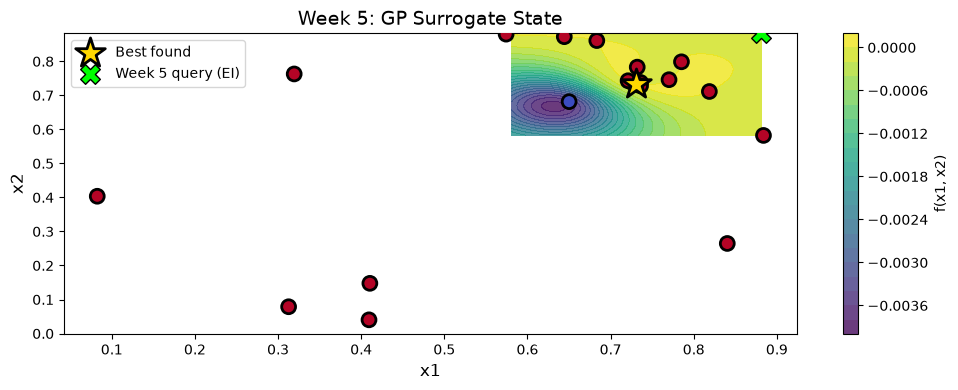

In [65]:
best_point   = X[np.argmax(Y)]
window       = 0.15
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

# xi_multiplier reduced sharply from 1.5 (Week 4) to 0.25 -- ~20:80 exploration:exploitation,
# reflecting the decisive shift to local refinement
result_w5     = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.25, week_label = 'Week 5'
)

next_point_w5 = result_w5['X_next']

# Week 6: Strategy Check
Compare EI candidates across window sizes, for reference. Kept for transparency - this is **NOT** the point ultimately submitted this

In [68]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)

best_point_check = X[np.argmax(Y)]
print("Learned kernel:", gp_check.kernel_)

grid_res = 150
for window in [0.15, 0.10, 0.05]:
    lo = np.clip(best_point_check - window, 0, 0.999999)
    hi = np.clip(best_point_check + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)

    xi = 0.1 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point_check)
    print(f"window=+/-{window}: EI-suggested next={candidates_local[idx]}, dist_to_best={dist:.4f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.15: EI-suggested next=[0.88102363 0.88299988], dist_to_best=0.2121, mu=-1.096e-04, EI=2.997e-04
window=+/-0.1: EI-suggested next=[0.83102363 0.83299988], dist_to_best=0.1414, mu=-2.024e-05, EI=1.963e-04
window=+/-0.05: EI-suggested next=[0.78102363 0.68299988], dist_to_best=0.0707, mu=-6.932e-05, EI=9.234e-05


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 6: Deliberate Proximity-Stability Test (Manual Override)
Rather than submitting the EI-selected point from the diagnostic above, this week deliberately queries a point extremely close to the current best, 
much closer than EI would ever choose on its own, since expected improvement collapses to near-zero right next to an existing sample. 

**Purpose:** Directly test whether (0.731, 0.733) sits on a genuine, sharp local peak (nearby point should also read strongly positive) or was an isolated single-point anomaly (nearby point should read near-zero or negative, like almost everything else in the dataset). Given only 2 queries
remain after this one, resolving this now, rather than continuing incremental EI refinement, leaves a full query in hand to act on whichever answer comes back.

In [71]:
best_point       = X[np.argmax(Y)]
offset           = np.array([-0.005, 0.005])
next_point_w6    = np.clip(best_point + offset, 0, 0.999999)

dist_to_best     = np.linalg.norm(next_point_w6 - best_point)
dist_to_nearest  = np.min(np.linalg.norm(X - next_point_w6, axis=1))

print("Current best point   :", best_point, "-> Output =", Y.max())
print("Week 6 query (manual):", next_point_w6)
print(f"Distance to best point       : {dist_to_best:.6f}")
print(f"Distance to nearest sample   : {dist_to_nearest:.6f}")

Current best point   : [0.73102363 0.73299988] -> Output = 7.710875114502849e-16
Week 6 query (manual): [0.72602363 0.73799988]
Distance to best point       : 0.007071
Distance to nearest sample   : 0.000000


# Week 7: Tight Local Refinement (Peak Stability Confirmed)

With the peak's stability confirmed, the plan from prior reflections applies directly: commit remaining queries to close, fine-grained refinement around
(0.731, 0.733) rather than treating this as an open exploration problem.

Testing several tight window sizes (+/-0.05, +/-0.02, +/-0.01) around the current best shows all of them consistently favouring a direction of **increasing x2** (toward 0.75-0.78) while keeping x1 close to the best (0.73-0.74), a consistent signal across window sizes. The predicted mean here is again higher than the current best, similar to the pattern seen before Week 5.

With very few queries left, the window is kept at +/-0.05 (not narrower) to still cover this newly-identified promising direction, while the exploration floor is cut further (xi_multiplier: 0.25 -> 0.05) to stay almost entirely exploitation-focused.


In [75]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

grid_res = 150
for window in [0.05, 0.02, 0.01]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.05 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    print(f"window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.4f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Learned kernel: 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.05: next=[0.78102363 0.68299988], dist_to_best=0.0707, mu=-6.932e-05, EI=1.069e-04
window=+/-0.02: next=[0.75102363 0.71299988], dist_to_best=0.0283, mu=-4.780e-06, EI=1.858e-05
window=+/-0.01: next=[0.7227686  0.72299988], dist_to_best=0.0130, mu=-1.094e-04, EI=2.890e-08


Local search bounds: [(np.float64(0.6810236309563585), np.float64(0.7810236309563586)), (np.float64(0.6829998764152272), np.float64(0.7829998764152273))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 7: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 3.929616e-05)
Next query point      : [0.78102363 0.68299988]
Acquisition value     : 1.069166e-04
Predicted mean (mu)   : -6.931587e-05
Predicted std (sigma) : 3.890625e-04
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


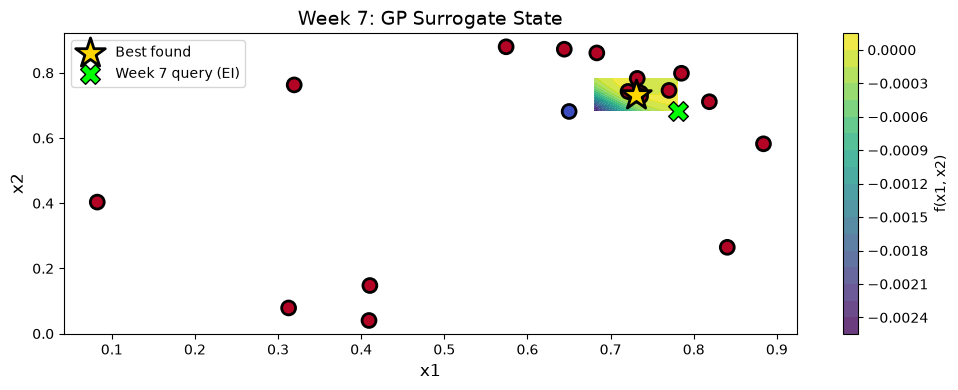

In [76]:
window       = 0.05
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

result_w7     = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.05, week_label = 'Week 7'
)

next_point_w7 = result_w7['X_next']

# Week 8: Strategy Check(The Peak Is Narrower Than Assumed )
Week 7's output, **-1.03e-24**, does not beat the current best. This is the third query within 0.09 of the best point to underperform. Sorting all 17
points by output value makes the pattern unambiguous.

Only **two** points are positive: the original best (0.731, 0.733) and Week 6's point (0.726, 0.738), just 0.007 apart. Every other point tested so
far,including three sitting only 0.04-0.09 away from the best (Week 3, Week 5, Week 7) turned out to be negative. This confirms an even **narrower**
peak than the Week 6/7 window sizes (+/-0.15, +/-0.05). This implies that the positive region appears to be confined to roughly a 0.01 radius, not 0.05.

**Direction not yet tested:** Every query so far has moved in x2 mostly or increased x1 while decreasing x2. The one query that increased x2 while keeping x1 close (Week 6, positive) suggests moving x1 in the other direction(slightly increasing both x1 and x2 together), is worth testing, since it't
the only nearby quadrant not yet sampled.

In [80]:
# Comparing window sizes down to +/-0.005

kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
for window in [0.02, 0.01, 0.005]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    print(f"window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.02: next=[0.75102363 0.71299988], dist_to_best=0.02828, mu=-4.780e-06, EI=2.713e-05
window=+/-0.01: next=[0.72827195 0.74299988], dist_to_best=0.01037, mu=7.490e-06, EI=1.664e-06
window=+/-0.005: next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-3.845e-05, EI=3.457e-08


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 8: Calling consolidated Bayesian Optimisation(Extremely Narrow Local Search)

Local search bounds: [(np.float64(0.7260236309563586), np.float64(0.7360236309563586)), (np.float64(0.7279998764152272), np.float64(0.7379998764152272))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 8: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.571846e-05)
Next query point      : [0.72602363 0.72799988]
Acquisition value     : 3.456563e-08
Predicted mean (mu)   : -3.845429e-05
Predicted std (sigma) : 2.112145e-05
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


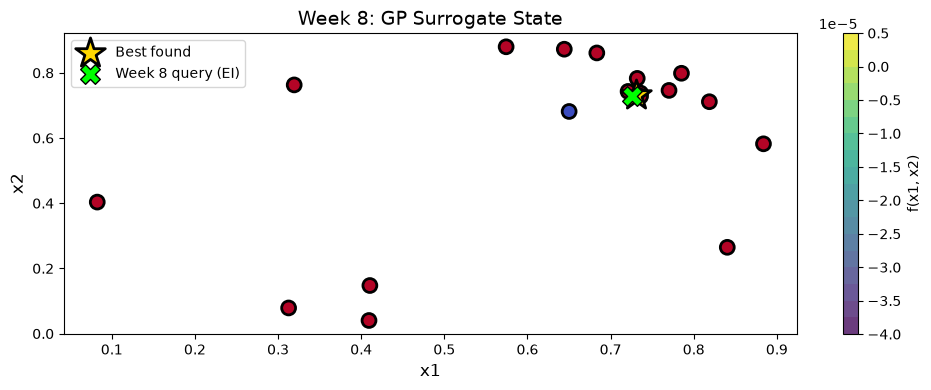

In [83]:
window       = 0.005
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

result_w8     = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.02, week_label = 'Week 8'
)

next_point_w8 = result_w8['X_next']

# Week 9: Strategy Check

Week 8's output[**1.166e-17**] does not beat the current best, but it is the **third positive point found**, and comparing it directly against Week 6 reveals a genuinely asymmetric peak:

| Point | x1, x2 | Output | x1 offset from best |
|---|---|---|---|
| Best | 0.731024, 0.732999 | 7.711e-16 | - |
| Week 6 | 0.726024, 0.738000 | **5.607e-16** | -0.005 |
| Week 8 | 0.736024, 0.738000 | **1.166e-17** | +0.005 |

Same x2 shift (+0.005) in both cases, opposite x1 direction, yet the output drops by roughly **48x** on the +x1 side compared to the -x1 side. This is concrete evidence the peak is steeper toward +x1 and smoother toward -x1.

**Checking what the GP's acquisition function and overriding it:** Re-fitting on all 18 points and evaluating EI over several tight windows points toward *decreasing* x2 while *increasing* x1 (e.g. ~0.751, 0.713), back in the same quadrant as Week 3's point (0.819, 0.711), which returned a negative result. Rather than following the GP's recommendation, the -x1 direction is extended further instead: since it is the only direction that has *twice* now shown a stronger reading closer to it (the original best itself, and Week 6), continuing past Week 6's point into un-sampled -x1 region is the more evidence-backed choice, even though EI itself doesn't currently recommend it.

In [87]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
for window in [0.02, 0.01, 0.005]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    print(f"window=+/-{window}: EI-suggested next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

Learned kernel: 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.02: EI-suggested next=[0.75102363 0.71299988], dist_to_best=0.02828, mu=-4.780e-06, EI=2.713e-05
window=+/-0.01: EI-suggested next=[0.72827195 0.74299988], dist_to_best=0.01037, mu=7.490e-06, EI=1.664e-06
window=+/-0.005: EI-suggested next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-3.845e-05, EI=3.457e-08


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


# Week 9: Manual Override

In [90]:
week6_point   = np.array([0.726024, 0.738000])
extend_offset = week6_point - best_point          # the -x1, +x2 direction that worked
next_point_w9 = np.clip(week6_point + extend_offset, 0, 0.999999)

dist_to_best      = np.linalg.norm(next_point_w9 - best_point)
dist_to_week6     = np.linalg.norm(next_point_w9 - week6_point)
dist_to_nearest   = np.min(np.linalg.norm(X - next_point_w9, axis=1))

print("Best point            :", best_point, "-> Output =", Y.max())
print("Week 6 point           :", week6_point, "-> Output =", 5.606704199651088e-16)
print("Week 9 query (manual)  :", next_point_w9)
print(f"Distance to best        : {dist_to_best:.6f}")
print(f"Distance to Week 6      : {dist_to_week6:.6f}")
print(f"Distance to nearest sample: {dist_to_nearest:.6f}")

Best point            : [0.73102363 0.73299988] -> Output = 7.710875114502849e-16
Week 6 point           : [0.726024 0.738   ] -> Output = 5.606704199651088e-16
Week 9 query (manual)  : [0.72102437 0.74300012]
Distance to best        : 0.014142
Distance to Week 6      : 0.007071
Distance to nearest sample: 0.000000


# Week 10: Strategy Check - confirming the peak's shape with a fourth nearby point

Week 9's output, **2.034e-16**, does not beat the current best, but laid alongside Week 6, it completes a genuine gradient signature along the -x1, +x2 direction:

| Point | x1, x2 offset from best | Output | Distance from best |
|---|---|---|---|
| Best | (0, 0) | 7.711e-16 | 0 |
| Week 6 | (-0.005, +0.005) | 5.607e-16 | 0.00707 |
| Week 9 | (-0.010, +0.010) | 2.034e-16 | 0.01414 |

This is **monotonically decreasing** as distance from best increases along this direction, evenly spaced (each step +0.00707 in distance). This is a strong evidence that the original best point is a genuine local maximum along this axis, not a point sitting on a slope that continues rising further out.
Week 8's point (+0.005, +0.005), by contrast, dropped by ~48x over the same distance, confirming real asymmetry rather than a coincidence.

**With 3 of 4 nearby quadrants now tested** (best itself, -x1/+x2 twice, +x1/+x2 once), the one direction never explored at this fine scale is x1 increasing, x2 decreasing. Re-running EI on the full 19-point dataset at the tightest window confirms this independently since EI's top candidate already fills the gap rather than repeating a direction already known to be unproductive.

In [94]:
kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
window_results = []
for window in [0.02, 0.01, 0.005]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    window_results.append((window, candidates_local[idx], dist, mu_l[idx], ei[idx]))
    print(f"window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Learned kernel: 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
window=+/-0.02: next=[0.75102363 0.71299988], dist_to_best=0.02828, mu=-4.780e-06, EI=2.713e-05
window=+/-0.01: next=[0.72827195 0.74299988], dist_to_best=0.01037, mu=7.490e-06, EI=1.664e-06
window=+/-0.005: next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-3.845e-05, EI=3.457e-08


# Week 10: Consolidated Bayesian Optimization (Untested Quadrant)

Local search bounds: [(np.float64(0.7260236309563586), np.float64(0.7360236309563586)), (np.float64(0.7279998764152272), np.float64(0.7379998764152272))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 10: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 1.571846e-05)
Next query point      : [0.72602363 0.72799988]
Acquisition value     : 3.456563e-08
Predicted mean (mu)   : -3.845429e-05
Predicted std (sigma) : 2.112145e-05
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


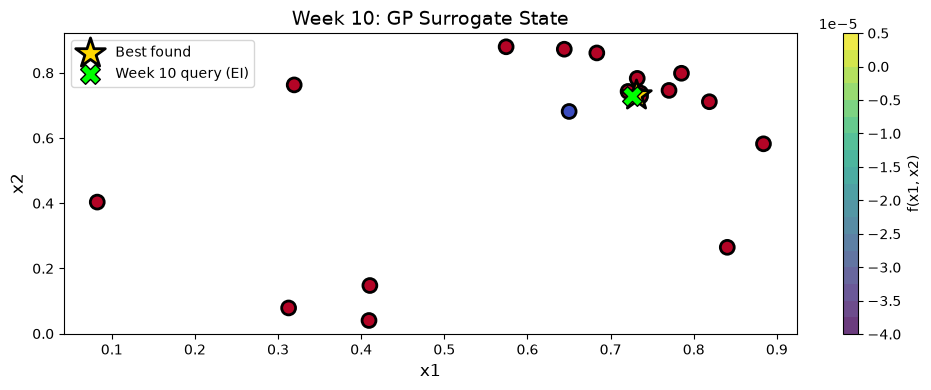

In [97]:
window       = 0.005
local_bounds = [
    (max(0.0, best_point[0] - window), min(0.999999, best_point[0] + window)),
    (max(0.0, best_point[1] - window), min(0.999999, best_point[1] + window)),
]
print("Local search bounds:", local_bounds)

result_w10    = bayesian_optimization_2d_step(
    X, Y, bounds = local_bounds,
    acquisition  = 'ei', xi_multiplier = 0.02, week_label = 'Week 10'
)

next_point_w10 = result_w10['X_next']

# Week 11: Strategy Check - the Basin Is Now Fully Bracketed

Week 10's feedback, **6.743944e-16**, is the **second-highest output found across all 20 points** — only ~0.97e-16 below the current best, and it confirms the one quadrant around the best that had never been tested at this fine scale. Laid out together, every immediate diagonal neighbour of the best within a 0.0141 radius is now accounted for:

| Point | x1, x2 offset from best | Output | Distance from best |
|---|---|---|---|
| Best | (0, 0) | 7.710875e-16 | 0 |
| Week 6 | (-0.005, +0.005) | 5.606704e-16 | 0.00707 |
| Week 9 | (-0.010, +0.010) | 2.033927e-16 | 0.01414 |
| Week 8 | (+0.005, +0.005) | 1.166379e-17 | 0.00707 |
| **Week 10** | **(+0.005, -0.005)** | **6.743944e-16** | **0.00707** |

**What this changes:** every one of the four diagonal directions tested at the ±0.005–0.01 scale is positive. A single best point surrounded by negative neighbours would be consistent with an isolated spike (possible noise); a best point surrounded on *all sides* by other positive points looks like a genuine, if narrow and asymmetric, local maximum **basin** — a small *cluster* of mutually-supporting positive observations rather than one lucky draw. The weak corner (Week 8, +x1/+x2) and the strong corner (Week 10, +x1/-x2) show the basin is elongated roughly along the -x2 axis and compressed along +x1 — i.e. not circularly symmetric.

**Strategy implication:** continuing to anchor the search purely on `argmax(Y)` (a single, possibly noisy, point) is no longer the most defensible choice now that there are five mutually-consistent positive observations describing the same basin. Section below introduces a small, transparent change: treat these points as a *cluster* and anchor the next query on the cluster's **output-weighted centroid** instead of the single best point. With only one query left after this week, this is also the last opportunity to correct the anchor before the final (Week 12) submission.

In [100]:
# Diagnostic - compare EI across shrinking windows around the current single-point best, for reference, before switching the anchor below.

kernel_check = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_check = GaussianProcessRegressor(kernel=kernel_check, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_check.fit(X, Y)
print("Learned kernel:", gp_check.kernel_)

best_point = X[np.argmax(Y)]
grid_res = 150
window_results_w11_bestpoint = []
for window in [0.01, 0.005, 0.003]:
    lo = np.clip(best_point - window, 0, 0.999999)
    hi = np.clip(best_point + window, 0, 0.999999)
    xs_l = np.linspace(lo[0], hi[0], grid_res)
    ys_l = np.linspace(lo[1], hi[1], grid_res)
    gxl, gyl = np.meshgrid(xs_l, ys_l)
    candidates_local = np.column_stack([gxl.ravel(), gyl.ravel()])
    mu_l, sigma_l = gp_check.predict(candidates_local, return_std=True)
    xi = 0.02 * Y.std()
    ei = expected_improvement(mu_l, sigma_l, Y.max(), xi)
    idx = np.argmax(ei)
    dist = np.linalg.norm(candidates_local[idx] - best_point)
    window_results_w11_bestpoint.append((window, candidates_local[idx], dist, mu_l[idx], ei[idx]))
    print(f"[single-point anchor] window=+/-{window}: next={candidates_local[idx]}, dist_to_best={dist:.5f}, "
          f"mu={mu_l[idx]:.3e}, EI={ei[idx]:.3e}")

C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Learned kernel: 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
[single-point anchor] window=+/-0.01: next=[0.72827195 0.74299988], dist_to_best=0.01037, mu=7.490e-06, EI=1.664e-06
[single-point anchor] window=+/-0.005: next=[0.72602363 0.72799988], dist_to_best=0.00707, mu=-3.845e-05, EI=3.457e-08
[single-point anchor] window=+/-0.003: next=[0.72802363 0.72999988], dist_to_best=0.00424, mu=-1.720e-05, EI=2.186e-09


# Week 11: Cluster-Informed Local Search (Strategy Update)

Rather than keep anchoring on `argmax(Y)` alone, this week uses **DBSCAN** (density-based clustering) on the sampled *spatial* coordinates (x1, x2) to separate a dense, mutually-close *promising* cluster from everything else, which DBSCAN explicitly labels as **noise** rather than forcing it into a cluster — a much closer match to what we actually believe about this function (one small real basin, surrounded by a background that is not a second structure, just background).

`eps` is chosen from the data itself, not guessed: a nearest-neighbour check (below) shows the five near-best points (best, Week 6, Week 8, Week 9, Week 10) are all within **0.0141** of at least one other member of the group, while the closest point *outside* that group sits **0.0414** away — a clear gap. Any `eps` between those two values (we use 0.02) cleanly recovers the same 5-point cluster and treats the other 15 points as noise.

The new query is then anchored on the **output-weighted centroid** of that cluster, not on the single largest point — a small but meaningful change: it treats the basin's shape as evidence in its own right, rather than relying on whichever single observation happens to be nominally highest (which, with outputs this close together and this small, could easily be swapped by noise).

In [105]:
# Cluster the sampled points into "promising" vs "background"
# DBSCAN on spatial coordinates (x1, x2): unlike KMeans, it does not force  every point into one of k groups.
# It finds dense regions and explicitly # labels everything else as noise (label -1), which matches this problem much
# better (one small real basin vs. a non-clustered background), as confirmed # by the nearest-neighbour gap check below.

from sklearn.cluster import DBSCAN

best_idx = np.argmax(Y)

# Nearest-neighbour distance check used to justify the eps choice below
D_all = squareform(pdist(X))
D_all_no_self = D_all + np.eye(len(X)) * 99
nn_dist = D_all_no_self.min(axis=1)
print("Nearest-neighbour distance for the current best point and its closest few:")
order_nn = np.argsort(D_all[best_idx])
for idx in order_nn[:6]:
    print(f"  idx {idx}: {X[idx]} -> y={Y[idx]:.3e}, dist_to_best={D_all[best_idx, idx]:.5f}")

dbscan = DBSCAN(eps=0.02, min_samples=2)
cluster_labels = dbscan.fit_predict(X)

promising_cluster = cluster_labels[best_idx]
promising_mask = cluster_labels == promising_cluster
noise_mask = cluster_labels == -1

print(f"\nDBSCAN found {len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)} dense cluster(s) "
      f"and {noise_mask.sum()} noise point(s) out of {len(X)} total.")
print(f"Promising cluster size: {promising_mask.sum()}")
print("\nPoints in the promising cluster:")
order = np.argsort(-Y[promising_mask])
for xi, yi in zip(X[promising_mask][order], Y[promising_mask][order]):
    print(f"  {xi} -> {yi:.6e}")

# Output-weighted centroid of the promising cluster (weights clipped at 0 --
# only the positive members pull the centroid, consistent with "higher is better")
w_cluster    = np.clip(Y[promising_mask], 0, None)
centroid_w11 = np.average(X[promising_mask], axis=0, weights=w_cluster)

print(f"\nOutput-weighted centroid of promising cluster (NEW anchor): {centroid_w11}")
print(f"Single-point best, argmax(Y)         (OLD anchor): {X[best_idx]}")
print(f"Shift between anchors: {np.linalg.norm(centroid_w11 - X[best_idx]):.6f}")

Nearest-neighbour distance for the current best point and its closest few:
  idx 2: [0.73102363 0.73299988] -> y=7.711e-16, dist_to_best=0.00000
  idx 15: [0.726024 0.738   ] -> y=5.607e-16, dist_to_best=0.00707
  idx 19: [0.736024 0.728   ] -> y=6.744e-16, dist_to_best=0.00707
  idx 17: [0.736024 0.738   ] -> y=1.166e-17, dist_to_best=0.00707
  idx 18: [0.721024 0.743   ] -> y=2.034e-16, dist_to_best=0.01414
  idx 14: [0.770285 0.746087] -> y=-4.704e-26, dist_to_best=0.04139

DBSCAN found 1 dense cluster(s) and 15 noise point(s) out of 20 total.
Promising cluster size: 5

Points in the promising cluster:
  [0.73102363 0.73299988] -> 7.710875e-16
  [0.736024 0.728   ] -> 6.743944e-16
  [0.726024 0.738   ] -> 5.606704e-16
  [0.721024 0.743   ] -> 2.033927e-16
  [0.736024 0.738   ] -> 1.166379e-17

Output-weighted centroid of promising cluster (NEW anchor): [0.73039044 0.7336859 ]
Single-point best, argmax(Y)         (OLD anchor): [0.73102363 0.73299988]
Shift between anchors: 0.000934


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


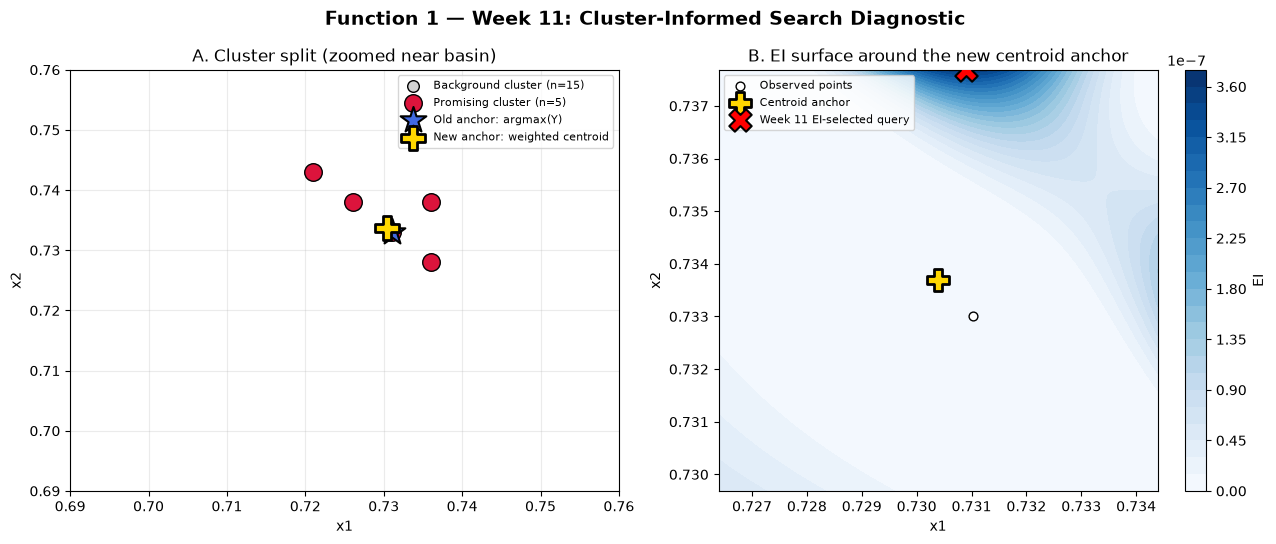

In [107]:
# Visualise the cluster split 

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Function 1 — Week 11: Cluster-Informed Search Diagnostic', fontsize=14, fontweight='bold')

# --- Panel A: cluster scatter, zoomed to the basin region ---
ax = axes[0]
ax.scatter(X[~promising_mask, 0], X[~promising_mask, 1], c='lightgray', edgecolor='black',
           s=70, label=f'Background cluster (n={(~promising_mask).sum()})', zorder=5)
ax.scatter(X[promising_mask, 0], X[promising_mask, 1], c='crimson', edgecolor='black',
           s=160, label=f'Promising cluster (n={promising_mask.sum()})', zorder=8)
ax.scatter(*X[best_idx], marker='*', s=380, c='royalblue', edgecolor='black',
           linewidths=1.5, label='Old anchor: argmax(Y)', zorder=10)
ax.scatter(*centroid_w11, marker='P', s=320, c='gold', edgecolor='black',
           linewidths=2, label='New anchor: weighted centroid', zorder=11)
ax.set_xlim(0.69, 0.76)
ax.set_ylim(0.69, 0.76)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('A. Cluster split (zoomed near basin)')
ax.legend(loc='upper right', fontsize=8)
ax.grid(alpha=0.25)

# --- Panel B: EI heatmap around the NEW centroid-anchored window ---
ax = axes[1]
window_w11 = 0.004
local_bounds_w11 = [
    (max(0.0, centroid_w11[0] - window_w11), min(0.999999, centroid_w11[0] + window_w11)),
    (max(0.0, centroid_w11[1] - window_w11), min(0.999999, centroid_w11[1] + window_w11)),
]
xs_b = np.linspace(local_bounds_w11[0][0], local_bounds_w11[0][1], 150)
ys_b = np.linspace(local_bounds_w11[1][0], local_bounds_w11[1][1], 150)
gxb, gyb = np.meshgrid(xs_b, ys_b)
cand_b = np.column_stack([gxb.ravel(), gyb.ravel()])

kernel_w11 = ConstantKernel(1.0) * Matern(length_scale=0.2, length_scale_bounds=(0.02, 1.0), nu=2.5) \
                + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))
gp_w11 = GaussianProcessRegressor(kernel=kernel_w11, normalize_y=True, n_restarts_optimizer=10, random_state=0)
gp_w11.fit(X, Y)
mu_b, sigma_b = gp_w11.predict(cand_b, return_std=True)
xi_b = 0.01 * Y.std()
ei_b = expected_improvement(mu_b, sigma_b, Y.max(), xi_b)

c = ax.contourf(gxb, gyb, ei_b.reshape(gxb.shape), levels=25, cmap='Blues')
fig.colorbar(c, ax=ax, label='EI')
ax.scatter(X[:, 0], X[:, 1], c='white', edgecolor='black', s=40, label='Observed points')
ax.scatter(*centroid_w11, marker='P', s=260, c='gold', edgecolor='black', linewidths=2, label='Centroid anchor')
best_idx_b = np.argmax(ei_b)
ax.scatter(*cand_b[best_idx_b], marker='X', s=260, c='red', edgecolor='black', linewidths=1.5,
           label='Week 11 EI-selected query', zorder=12)
ax.set_xlim(local_bounds_w11[0])
ax.set_ylim(local_bounds_w11[1])
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('B. EI surface around the new centroid anchor')
ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

# Week 11: Consolidated Bayesian Optimisation (Centroid-Anchored)

Running the existing `bayesian_optimization_2d_step` helper (unchanged from Week 3 onward) with the new centroid-based anchor and a further-tightened window (+/-0.004, down from Week 10's +/-0.005) and exploration floor (`xi_multiplier`=0.01, down from 0.02) — reflecting both the stronger evidence base (20 points vs. 19) and the now near-exhausted query budget (one query left after this week).

Week 11 local search bounds (centred on cluster centroid): [(np.float64(0.726390438488297), np.float64(0.734390438488297)), (np.float64(0.7296859014904112), np.float64(0.7376859014904112))]


C:\Users\mitra\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-10. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


--- Week 11: Bayesian Optimization ---
Learned kernel        : 1.33**2 * Matern(length_scale=0.09, nu=2.5) + WhiteKernel(noise_level=1e-10)
Acquisition           : EI (xi = 7.859231e-06)
Next query point      : [0.73090051 0.7376859 ]
Acquisition value     : 3.600918e-07
Predicted mean (mu)   : 4.108121e-06
Predicted std (sigma) : 3.942947e-06
Best value so far     : 7.710875e-16 at [0.73102363 0.73299988]


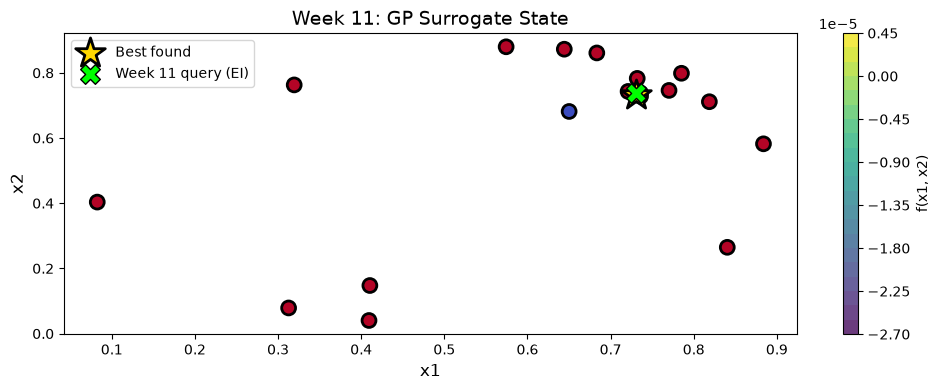


Week 11 query (centroid-anchored EI): [0.73090051 0.7376859 ]
Distance from old anchor (argmax best): 0.004688
Distance from new anchor (centroid)   : 0.004032


In [110]:
# Consolidated BO call using the cluster-weighted centroid as the search anchor instead of the single-point best used in Weeks 5-10.
print("Week 11 local search bounds (centred on cluster centroid):", local_bounds_w11)

result_w11 = bayesian_optimization_2d_step(
    X, Y, bounds=local_bounds_w11,
    acquisition='ei', xi_multiplier=0.01, week_label='Week 11'
)

next_point_w11 = result_w11['X_next']
print(f"\nWeek 11 query (centroid-anchored EI): {next_point_w11}")
print(f"Distance from old anchor (argmax best): {np.linalg.norm(next_point_w11 - X[best_idx]):.6f}")
print(f"Distance from new anchor (centroid)   : {np.linalg.norm(next_point_w11 - centroid_w11):.6f}")

# Portal Submission 

In [112]:
# Format as required by the capstone portal: x1-x2 (6 decimal places)
submission_str = f"{next_point_w11[0]:.6f}-{next_point_w11[1]:.6f}"
print("Points to be submitted (Week 1) :", '0.644295-0.872483')
print("Points to be submitted (Week 2) :", '0.785234-0.798657')
print("Points to be submitted (Week 3) :", '0.818791-0.711409')
print("Points to be submitted (Week 4) :", '0.409396-0.040268')
print("Points to be submitted (Week 5) :", '0.770285-0.746087')
print("Points to be submitted (Week 6) :", '0.726024-0.738000')
print("Points to be submitted (Week 7) :", '0.732030-0.783000')
print("Points to be submitted (Week 8) :", '0.736024-0.738000')
print("Points to be submitted (Week 9) :", '0.721024-0.743000')
print("Points to be submitted (Week 10):", '0.736024-0.728000')
print("Points to be submitted (Week 11):", submission_str)
print()

Points to be submitted (Week 1) : 0.644295-0.872483
Points to be submitted (Week 2) : 0.785234-0.798657
Points to be submitted (Week 3) : 0.818791-0.711409
Points to be submitted (Week 4) : 0.409396-0.040268
Points to be submitted (Week 5) : 0.770285-0.746087
Points to be submitted (Week 6) : 0.726024-0.738000
Points to be submitted (Week 7) : 0.732030-0.783000
Points to be submitted (Week 8) : 0.736024-0.738000
Points to be submitted (Week 9) : 0.721024-0.743000
Points to be submitted (Week 10): 0.736024-0.728000
Points to be submitted (Week 11): 0.730901-0.737686



# Plot the Progress of the optimisation process

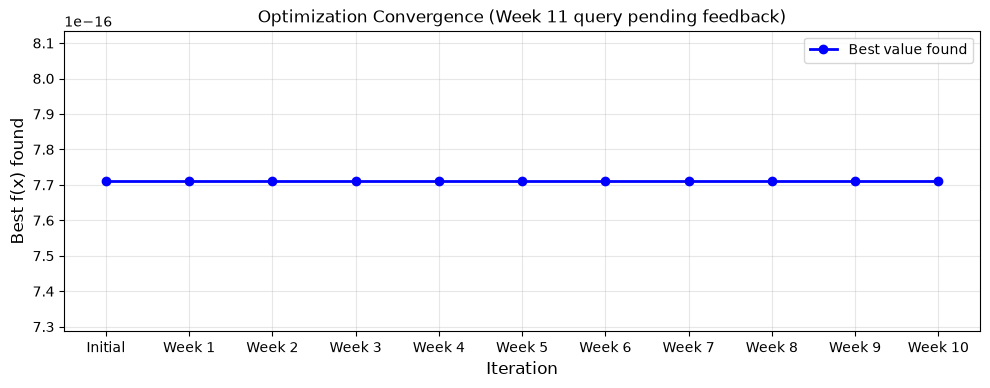

Best value found so far (through Week 10): 7.710875114502849e-16
Week 10's output (6.743944e-16) is the SECOND-HIGHEST value found across all 20 points.


In [115]:
# Track best-value-found progress across weeks

best_so_far = [
    7.710875114502849e-16,                                   # best after initial 10 points
    max(7.710875114502849e-16, -4.57919574117409e-42),       # best after Week 1
    max(7.710875114502849e-16, 1.1704238583798859e-37),      # best after Week 2
    max(7.710875114502849e-16, -5.679811964041589e-31),      # best after Week 3
    max(7.710875114502849e-16, -6.7375004083242144e-102),    # best after Week 4
    max(7.710875114502849e-16, -4.7039714109697477e-26),     # best after Week 5
    max(7.710875114502849e-16, 5.606704199651088e-16),       # best after Week 6
    max(7.710875114502849e-16, -1.0284805649443051e-24),     # best after Week 7
    max(7.710875114502849e-16, 1.1663787782344231e-17),      # best after Week 8
    max(7.710875114502849e-16, 2.0339265002274336e-16),      # best after Week 9
    max(7.710875114502849e-16, 6.743943716784949e-16),       # best after Week 10 -- WEEK 11 ADDITION
]

fig, ax     = plot_convergence(range(len(best_so_far)), best_so_far)
ax.set_xticks(range(len(best_so_far)))
ax.set_xticklabels(['Initial', 'Week 1', 'Week 2', 'Week 3', 'Week 4', 'Week 5', 'Week 6', 'Week 7', 'Week 8', 'Week 9', 'Week 10'])
ax.set_title(ax.get_title() + ' (Week 11 query pending feedback)')
plt.show()

print("Best value found so far (through Week 10):", max(best_so_far))
print("Week 10's output (6.743944e-16) is the SECOND-HIGHEST value found across all 20 points.")

Weekly Master Dashboard

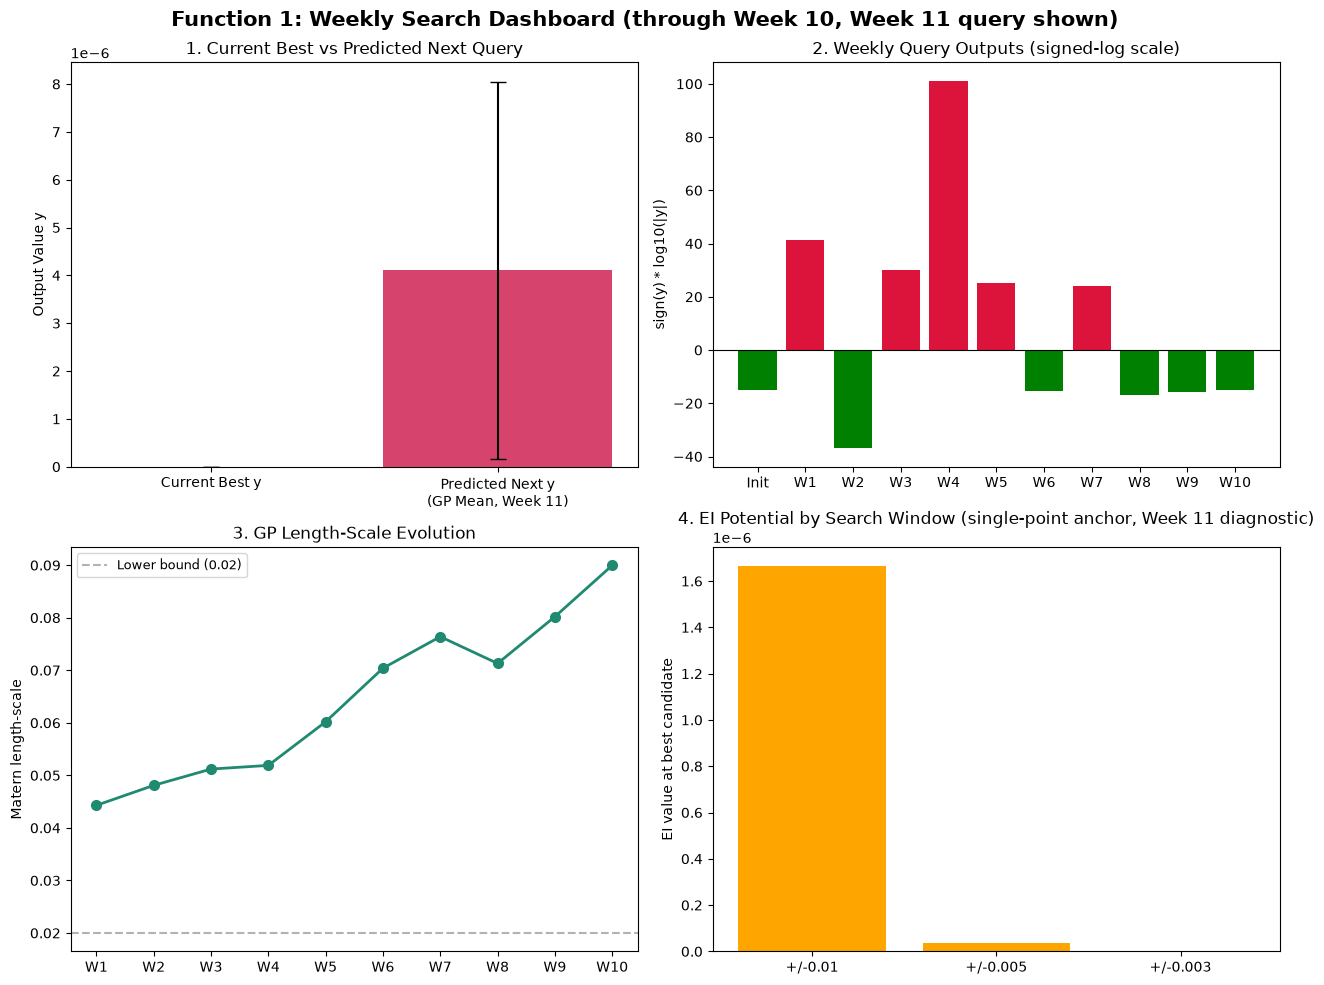

In [119]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle('Function 1: Weekly Search Dashboard (through Week 10, Week 11 query shown)', fontsize=15, fontweight='bold')

# --- Panel 1: current best vs predicted next query output (Week 11 anchor) ---
ax = axes[0, 0]
current_best   = Y.max()
predicted_mu   = result_w11['mu_at_next']
predicted_std  = result_w11['sigma_at_next']
bars = ax.bar(['Current Best y', 'Predicted Next y\n(GP Mean, Week 11)'],
              [current_best, predicted_mu],
              yerr=[0, predicted_std], capsize=6,
              color=['#1f2d5c', '#d6446d'])
ax.set_ylabel('Output Value y')
ax.set_title('1. Current Best vs Predicted Next Query')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

# --- Panel 2: weekly optimisation trajectory (signed-log magnitude) ---
ax = axes[0, 1]
weekly_outputs = [7.710875114502849e-16, -4.57919574117409e-42, 1.1704238583798859e-37,
                  -5.679811964041589e-31, -6.7375004083242144e-102, -4.7039714109697477e-26,
                  5.606704199651088e-16, -1.0284805649443051e-24, 1.1663787782344231e-17,
                  2.0339265002274336e-16, 6.743943716784949e-16]   # <-- WEEK 11 ADDITION: Week 10 actual
labels = ['Init', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9', 'W10']
signed_log = [np.sign(v) * np.log10(abs(v) + 1e-300) for v in weekly_outputs]
colors = ['green' if v > 0 else 'crimson' for v in weekly_outputs]
ax.bar(labels, signed_log, color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('sign(y) * log10(|y|)')
ax.set_title('2. Weekly Query Outputs (signed-log scale)')
ax.tick_params(axis='x', rotation=0)

# --- Panel 3: kernel length-scale evolution ---
ax = axes[1, 0]
lengthscale_history = [0.0443, 0.0481, 0.0512, 0.0519, 0.0602, 0.0704, 0.0764, 0.0713, 0.0802, gp_w11.kernel_.k1.k2.length_scale]
ax.plot(labels[1:], lengthscale_history, 'o-', color='#1f8a70', linewidth=2, markersize=7)
ax.axhline(0.02, color='gray', linestyle='--', alpha=0.6, label='Lower bound (0.02)')
ax.set_ylabel('Matern length-scale')
ax.set_title('3. GP Length-Scale Evolution')
ax.legend(loc='upper left', fontsize=9)

# --- Panel 4: EI potential across window sizes, centroid-anchored (Week 11) ---
ax = axes[1, 1]
windows = [w[0] for w in window_results_w11_bestpoint]
ei_vals = [w[4] for w in window_results_w11_bestpoint]
ax.bar([f'+/-{w}' for w in windows], ei_vals, color='orange')
ax.set_ylabel('EI value at best candidate')
ax.set_title('4. EI Potential by Search Window (single-point anchor, Week 11 diagnostic)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))

plt.tight_layout()
plt.show()